# Carrito autónomo de doble cara — Simulación y entrenamiento con SARSA

**Objetivo:** lanzar el carrito en una cancha de fútbol; cae en un punto desconocido, **derecho o al revés**, y debe llegar **solo** (sin control remoto) a menos de **2 m** de la persona, idealmente en **menos de 4 minutos**.

**Hardware que se simula** (lo único que el agente puede "ver"):

| Componente | Qué aporta | Cómo se simula |
|---|---|---|
| GPS NEO-6M en el carrito | posición del carrito | posición real + error lento que deriva (~2 m) + ruido rápido (0.3 m), 1 lectura/s |
| GPS NEO-6M en la persona (+ LoRa) | posición de la persona | igual que arriba. LoRa no se simula: la persona está quieta, basta la última coordenada recibida |
| MPU6050 – acelerómetro | ¿está al revés? y golpes (choques) | detecta el golpe con 90 % de probabilidad; 0.5 % de falsos golpes por baches |
| MPU6050 – giroscopio | cuánto giró | giro real + error de 3° por giro + deriva 0.1°/s |
| 2 motorreductores + puente H | movimiento | tracción diferencial a **0.3 m/s**, giros de ~45°; el pasto añade ruido |
| Chasis de doble cara, 2 ruedas locas | funciona por ambas caras | **al revés se invierten** avanzar↔retroceder e izquierda↔derecha |

> **El MPU6050 no tiene brújula.** El carrito no sabe hacia dónde mira cuando cae. Solución: al recorrer una recta de 4 m, el desplazamiento GPS da el rumbo; desde ahí el giroscopio lo actualiza. Mientras tanto el estado dice *"rumbo desconocido"* y el agente aprende qué hacer en ese caso.

Archivos: `cancha_env.py` (entorno Gymnasium), `sarsa.py` (SARSA tabular y semi-gradiente), este notebook, y `resultados/` (CSV, GIF).

In [1]:
import math, time, os
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from matplotlib import animation, patches
from IPython.display import HTML, display
import cancha_env as ce, sarsa
plt.rcParams.update({"figure.dpi": 90, "axes.grid": True, "grid.alpha": .3})
SALIDA = "resultados"; os.makedirs(SALIDA, exist_ok=True)
print("Estados:", ce.N_ESTADOS, "| Acciones:", len(ce.NOMBRES_ACCION), "| Tamaño de la tabla Q:", ce.N_ESTADOS * 4, "valores")

Estados: 144 | Acciones: 4 | Tamaño de la tabla Q: 576 valores


## 1. Formulación del MDP (Unidad 1)

### Estado $S$ — solo con lo que los sensores pueden saber
$$S = (\,d,\ \phi,\ F,\ B\,)$$

| Variable | Significado | Valores |
|---|---|---|
| $d$ | distancia entre los 2 GPS | `<5 m`, `5–15 m`, `15–40 m`, `>40 m` (4) |
| $\phi$ | hacia dónde está la persona respecto a la nariz del carrito: $\text{rumbo a la meta} - \text{rumbo estimado}$ | 8 sectores de 45° + **"rumbo desconocido"** (9) |
| $F$ | volteado (acelerómetro) | 0 derecho / 1 al revés (2) |
| $B$ | bloqueado: chocó hace poco (golpe en el acelerómetro o el GPS no avanza aunque los motores empujan) | 0 / 1 (2) |

Total $4 \times 9 \times 2 \times 2 = 144$ estados $\Rightarrow$ la tabla Q tiene $144 \times 4 = 576$ números (cabe en cualquier tarjeta).

No se usan coordenadas absolutas: la persona y el carrito pueden estar en cualquier sitio, así que el estado es **relativo** (distancia y ángulo). Por eso la misma tabla sirve sin importar dónde estén.

### Acciones $A$ (cada una dura 1 s, una lectura de GPS)
`0 Avanzar` · `1 Retroceder` · `2 Girar izquierda` · `3 Girar derecha`

### Dinámica $p(s', r \mid s, a)$ — desconocida para el agente (model-free)
- Avanzar mueve 0.3 m en la dirección de la nariz… **excepto si $F=1$**, donde se mueve hacia atrás. Lo mismo con los giros.
- Si hay un obstáculo, las ruedas giran pero el carrito no avanza.
- Todo con ruido (pasto, GPS, giroscopio) → por eso se aprende con **muestras** (SARSA) y no con Programación Dinámica.

### Recompensa $R$ (idea del equipo: premiar que la distancia disminuya)
$$R_{t+1} = \underbrace{3\,(d^{GPS}_t - d^{GPS}_{t+1})}_{\text{se acercó}} \; \underbrace{-\,1}_{\text{cada segundo}} \; \underbrace{-\,5}_{\text{choque}} \; \underbrace{+\,100}_{\text{llegó } (<2\text{ m})} \; \underbrace{-\,50}_{\text{se salió}}$$

Episodio termina al llegar o salir de la cancha; se corta a los 10 min (600 pasos).

### Retorno y descuento
$G_t = \sum_k \gamma^k R_{t+k+1} = R_{t+1} + \gamma G_{t+1}$, con $\gamma$ entre 0.9 y 0.99 (se compara abajo). En el entrenamiento se guarda $G_0$ de cada episodio.

### Tarea episódica
Tiene final natural: estado terminal al **llegar** (`terminated`) o **salirse** (`terminated`); si pasan 10 min se corta (`truncated`, como en Gymnasium). Por eso $\gamma<1$ no es obligatorio, pero ayuda: hace que +100 hoy valga más que +100 en 5 min (el robot no pierde el tiempo) y estabiliza el aprendizaje.

### ¿Cumple la propiedad de Markov?
La propiedad pide que el estado resuma **todo** lo relevante del pasado: $P(S_{t+1}\mid S_t,A_t) = P(S_{t+1}\mid S_0,A_0,\dots,S_t,A_t)$.

Con sensores baratos el mundo **no** es totalmente observable (el agente no ve su posición exacta ni el error del GPS). Lo que se hizo para acercarse a Markov:

| Información del pasado que importa | Cómo se mete en el estado actual |
|---|---|
| Hacia dónde mira el carrito (no hay brújula) | La tarjeta **guarda en memoria** el rumbo estimado (recta GPS + giroscopio integrado) y el estado usa $\phi$ = ángulo a la persona relativo a ese rumbo. Si aún no hay rumbo, $\phi$ = "desconocido". |
| Si chocó hace poco | Bandera $B$: se mantiene en 1 hasta recorrer 6 s en recta sin golpes. |
| Cayó al revés | $F$ lo da el acelerómetro en cada instante. |

Así la política depende **solo del estado actual** $\pi(s)$ → es una política válida (no del tipo "alternar izquierda y derecha", que depende del paso anterior). Lo que queda sin observar (error del GPS, posición exacta dentro de cada rango de distancia) aparece como **ruido** en $p(s',r\mid s,a)$, y SARSA, al aprender de muestras, lo tolera.

### ¿Por qué SARSA y no Programación Dinámica?
La PD (iteración de política / de valor) necesita conocer $p(s',r\mid s,a)$ exacta para los 144 estados. Aquí esa dinámica depende del pasto, del error del GPS, del giroscopio, de dónde haya obstáculos… nadie la puede escribir. Abajo se muestra: la **misma** pareja $(s,a)$ lleva a estados y recompensas distintos. SARSA es **model-free**: aprende directamente de la experiencia $(S,A,R,S',A')$, sin la tabla de probabilidades.

In [2]:
from collections import Counter, defaultdict

def nombre_estado(s):
    d, a, f, b = ce.decodificar_estado(s)
    return f"{ce.NOMBRES_DIST[d]}, persona {ce.NOMBRES_ANG[a]}, {'al revés' if f else 'derecho'}, {'bloqueado' if b else 'libre'}"

# muestras (s, a) -> (s', r) con acciones al azar: la dinámica estimada por conteo
trans, recs = defaultdict(Counter), defaultdict(list)
env, rng = ce.CanchaEnv(), np.random.default_rng(1)
for ep in range(300):
    s, _ = env.reset(seed=ep)
    for _ in range(200):
        a = int(rng.integers(4))
        s2, r, term, trunc, _ = env.step(a)
        trans[(s, a)][s2] += 1; recs[(s, a)].append(r)
        s = s2
        if term or trunc: break

s0, a0 = max((k for k in trans if k[1] == ce.AVANZAR), key=lambda k: sum(trans[k].values()))
n = sum(trans[(s0, a0)].values())
print(f"S = {nombre_estado(s0)} | A = Avanzar   ({n} muestras)")
print(f"R: media {np.mean(recs[(s0, a0)]):.2f}, desviación {np.std(recs[(s0, a0)]):.2f}  (no es fija)")
pd.DataFrame([{"S'": nombre_estado(s2), "p(S'|S,A) estimada": round(c / n, 3)} for s2, c in trans[(s0, a0)].most_common(6)])

S = >40 m, persona rumbo ?, al revés, libre | A = Avanzar   (4283 muestras)
R: media -0.91, desviación 2.48  (no es fija)


,S',"p(S'|S,A) estimada"
0,">40 m, persona rumbo ?, al revés, libre",0.982
1,"15-40 m, persona rumbo ?, al revés, libre",0.013
2,">40 m, persona rumbo ?, al revés, bloqueado",0.005


## 2. El entorno (Gymnasium) y pruebas de que la física es correcta

In [3]:
%run test_cancha_env.py
%run test_sarsa.py

env = ce.CanchaEnv()
s, _ = env.reset(seed=42)
print("observation_space:", env.observation_space, "| action_space:", env.action_space)
print("Estado inicial:", s, "->", dict(zip(["dist", "ang", "volteado", "bloqueado"], ce.decodificar_estado(s))))
s, r, term, trunc, info = env.step(ce.AVANZAR)
print("Tras 'Avanzar': estado", s, "| recompensa", round(r, 2), "|", info)

OK


OK
observation_space: Discrete(144) | action_space: Discrete(4)
Estado inicial: 140 -> {'dist': 3, 'ang': 8, 'volteado': 0, 'bloqueado': 0}
Tras 'Avanzar': estado 140 | recompensa 2.04 | {'llego': False, 'fuera': False, 'choque': False, 't': 1.0, 'dist_real': 59.684999706338715}


### Funciones para dibujar la cancha y animar un lanzamiento

In [4]:
def dibujar_cancha(ax):
    ax.add_patch(patches.Rectangle((-3, -3), ce.LARGO + 6, ce.ANCHO + 6, color="#3a8f3a", zorder=0))
    lw = dict(color="white", lw=1.2, fill=False, zorder=1)
    ax.add_patch(patches.Rectangle((0, 0), ce.LARGO, ce.ANCHO, **lw))
    ax.plot([ce.LARGO / 2] * 2, [0, ce.ANCHO], color="white", lw=1.2, zorder=1)
    ax.add_patch(patches.Circle((ce.LARGO / 2, ce.ANCHO / 2), 9.15, **lw))
    for x0, s in ((0, 1), (ce.LARGO, -1)):
        ax.add_patch(patches.Rectangle((x0, ce.ANCHO / 2 - 20.16), s * 16.5, 40.32, **lw))
        ax.add_patch(patches.Rectangle((x0, ce.ANCHO / 2 - 9.16), s * 5.5, 18.32, **lw))
    ax.set(xlim=(-3, ce.LARGO + 3), ylim=(-3, ce.ANCHO + 3), aspect="equal")
    ax.grid(False); ax.set_xticks([]); ax.set_yticks([])


def dibujar_mundo(ax, env):
    dibujar_cancha(ax)
    for ox, oy, r in env.obstaculos:
        ax.add_patch(patches.Circle((ox, oy), r, color="#555", zorder=2))
    ax.plot(*env.meta, marker="*", color="red", ms=18, mec="white", zorder=5)
    ax.add_patch(patches.Circle(env.meta, ce.RADIO_META, color="red", alpha=.25, zorder=2))


def animar(fotos, acciones, env, titulo, max_cuadros=110, archivo=None):
    salto = max(1, len(fotos) // max_cuadros)
    idx = list(range(0, len(fotos), salto)) + ([len(fotos) - 1] if (len(fotos) - 1) % salto else [])
    fig, ax = plt.subplots(figsize=(9, 6.2), dpi=72)
    dibujar_mundo(ax, env)
    tray, = ax.plot([], [], color="yellow", lw=2, zorder=3, label="recorrido real")
    gps, = ax.plot([], [], ".", color="cyan", ms=3, zorder=3, label="lecturas GPS del carrito")
    gmeta, = ax.plot([], [], "x", color="red", ms=6, zorder=4, label="GPS de la persona")
    carro = patches.Polygon([[0, 0]] * 3, closed=True, zorder=6, ec="black")
    ax.add_patch(carro)
    txt = ax.text(0.01, 0.99, "", transform=ax.transAxes, va="top", fontsize=9, family="monospace",
                  bbox=dict(fc="white", alpha=.85), zorder=7)
    ax.set_title(titulo); ax.legend(loc="lower right", fontsize=8)

    def cuadro(k):
        i = idx[k]; f = fotos[i]
        xs = [g["pos"][0] for g in fotos[:i + 1]]; ys = [g["pos"][1] for g in fotos[:i + 1]]
        tray.set_data(xs, ys)
        gps.set_data([g["gps_car"][0] for g in fotos[:i + 1]], [g["gps_car"][1] for g in fotos[:i + 1]])
        gmeta.set_data([f["gps_meta"][0]], [f["gps_meta"][1]])
        x, y, t = *f["pos"], f["theta"]
        L = 2.2  # dibujado mas grande que el real para que se vea
        carro.set_xy([[x + L * math.cos(t), y + L * math.sin(t)],
                      [x + L * .6 * math.cos(t + 2.4), y + L * .6 * math.sin(t + 2.4)],
                      [x + L * .6 * math.cos(t - 2.4), y + L * .6 * math.sin(t - 2.4)]])
        carro.set_facecolor("#a020f0" if f["volteado"] else "orange")
        dg = math.dist(f["gps_car"], f["gps_meta"])
        acc = ce.NOMBRES_ACCION[acciones[i - 1]] if i else "-"
        rumbo = "desconocido" if f["rumbo_est"] is None else f"{math.degrees(f['rumbo_est']):6.0f}°"
        txt.set_text(f"t = {i:3d} s   accion: {acc}\n"
                     f"dist GPS {dg:5.1f} m | real {math.dist(f['pos'], env.meta):5.1f} m\n"
                     f"{'AL REVES (morado)' if f['volteado'] else 'derecho (naranja)'} | rumbo est.: {rumbo}\n"
                     f"bloqueado: {'SI' if f['bloqueado'] else 'no'}")
        return tray, gps, gmeta, carro, txt

    an = animation.FuncAnimation(fig, cuadro, frames=len(idx), interval=120, blit=True)
    if archivo:
        an.save(os.path.join(SALIDA, archivo), writer=animation.PillowWriter(fps=8), dpi=70)
    plt.close(fig)
    return HTML(an.to_jshtml(default_mode="once"))

### Antes de aprender: un agente aleatorio
Así se ve un lanzamiento con acciones al azar (el triángulo es el carrito; **naranja = derecho, morado = al revés**; la estrella roja es la persona).

In [5]:
class Aleatorio:
    def __init__(self): self.rng = np.random.default_rng(0)
    def mejor(self, s): return int(self.rng.integers(4))

info, env_a, fotos, acc = sarsa.correr(Aleatorio(), seed=5, guardar=True)
print("Agente aleatorio:", "llegó" if info["llego"] else ("se salió" if info["fuera"] else "no llegó en 10 min"),
      f"| distancia real final {info['dist_real']:.1f} m")
animar(fotos, acc, env_a, "Agente ALEATORIO (sin entrenar)", max_cuadros=60)

Agente aleatorio: no llegó en 10 min | distancia real final 41.3 m


## 3. SARSA (Unidad 2) — control on-policy por Diferencia Temporal

$$Q(S_t,A_t) \leftarrow Q(S_t,A_t) + \alpha\big[R_{t+1} + \gamma\,Q(S_{t+1},A_{t+1}) - Q(S_t,A_t)\big]$$

- **On-policy:** $A_{t+1}$ es la acción que **realmente** toma la política $\varepsilon$-greedy, así que aprende rutas que toleran sus propios errores de exploración (más seguro para un robot físico que Q-Learning).
- **Política $\varepsilon$-greedy:** con probabilidad $\varepsilon$ explora (acción al azar), si no explota $\arg\max_a Q(s,a)$.
- **Optimismo:** iniciar $Q_0 > 0$ hace que las acciones no probadas parezcan buenas → más exploración.
- **$\alpha$ decreciente:** como el GPS hace la recompensa ruidosa, bajar $\alpha$ al final estabiliza la tabla. Se prueban dos formas: lineal hasta el 10 % y la de la Tarea 9, $\alpha(ep) = \dfrac{\alpha_0}{1 + 0.0005\cdot ep}$.

### On-policy vs off-policy (por qué SARSA)
| | SARSA (on-policy) | Q-Learning (off-policy, **no se usa**) |
|---|---|---|
| Objetivo TD | $R + \gamma\,Q(S',A')$, con $A'$ la acción que **sí** tomará | $R + \gamma \max_a Q(S',a)$ |
| Aprende el valor de… | la política que realmente sigue (con su exploración) | la política greedy ideal |
| En CliffWalking | ruta **segura**, lejos del acantilado | ruta pegada al borde |

Para el carrito, el "acantilado" es la **línea de la cancha** (−50) y los obstáculos: SARSA aprende a no arriesgarse cerca de ellos sabiendo que a veces se equivoca (GPS, exploración). Por eso se eligió SARSA.

### Variante: Expected SARSA (Unidad 2)
En vez de usar la acción $A'$ que salió, usa el **promedio** sobre lo que haría la política $\varepsilon$-greedy:
$$Q(S_t,A_t) \leftarrow Q(S_t,A_t) + \alpha\Big[R_{t+1} + \gamma\sum_a \pi(a\mid S_{t+1})\,Q(S_{t+1},a) - Q(S_t,A_t)\Big],\qquad \pi(a\mid s)=\tfrac{\varepsilon}{|A|} + (1-\varepsilon)\,[a = \arg\max Q]$$
Menos varianza (no depende de un sorteo), un poco más de cálculo.

### Exploración con UCB (Unidad 1)
En lugar de explorar al azar, se elige la acción con mayor "límite superior de confianza" en cada estado:
$$A_t = \arg\max_a\Big[Q(S_t,a) + c\sqrt{\tfrac{\ln t}{N(S_t,a)}}\Big]$$
Las acciones poco probadas en ese estado reciben un bono; las nunca probadas se eligen primero.

Código del entrenamiento (de `sarsa.py`):

In [6]:
import inspect
print(inspect.getsource(sarsa.entrenar))

def entrenar(cfg):
    """SARSA on-policy (o Expected SARSA) con epsilon-greedy o UCB. Devuelve (agente, historial)."""
    cfg = {**BASE, **cfg}
    assert not (cfg["algoritmo"] == "esarsa" and cfg["eps"] == "ucb"), "Expected SARSA necesita pi(a|s): usar epsilon"
    env = ce.CanchaEnv(recompensa=cfg["recompensa"])
    rng = random.Random(cfg["semilla"])
    ag = Agente(cfg)
    g = cfg["gamma"]
    hist = {"recompensa": [], "retorno": [], "llego": [], "tiempo": []}

    def elegir(s, eps):
        if cfg["eps"] == "ucb":  # Unidad 1: argmax Q + c sqrt(ln t / N(s,a)); primero las nunca probadas
            ag.t += 1
            n, q = ag.N[s], ag.q(s)
            a = n.index(0) if 0 in n else max(range(4), key=lambda b: q[b] + cfg["c_ucb"] * math.sqrt(math.log(ag.t) / n[b]))
            n[a] += 1
            return a
        return rng.randrange(4) if rng.random() < eps else ag.mejor(s)

    for ep in range(cfg["episodios"]):
        eps = epsilon(cfg, ep)
        ag.alpha = tasa(cfg,

## 4. Experimentos: decidir hiperparámetros, recompensa y política

Se parte de una configuración base y se cambia **un factor a la vez**. Cada configuración se entrena 15 000 episodios con **10 semillas distintas** (el GPS hace que un solo entrenamiento sea engañoso; en clase el *10-armed testbed* repite 2000 veces por lo mismo) y se evalúa con 400 lanzamientos nuevos con la política *greedy* ($\varepsilon = 0$, como en la tarjeta). La tabla muestra la media de las 10 semillas, `±` su desviación y `IC95` el intervalo de confianza del 95 % de la media ($1.96\,\sigma/\sqrt{10}$). En las curvas, la banda sombreada es ± una desviación entre semillas.

Base: `SARSA, α=0.1 (decreciente lineal), γ=0.95, ε: 1.0→0.05, Q₀=0, recompensa = progreso + tiempo`.

| Grupo | Qué se compara (temas de clase) |
|---|---|
| α | tamaño del paso |
| Decaimiento de α | constante, lineal, fórmula de la Tarea 9 |
| γ | agente miope vs previsor |
| ε | greedy puro (0), 0.01, 0.1, 0.2 y decreciente — como el *10-armed testbed* |
| UCB vs ε-greedy | exploración dirigida por incertidumbre ($c=2$ y $c=20$, porque aquí las Q valen decenas) |
| Q₀ | inicialización optimista 0, 20, 50, 100, y optimista **sin** ε (Q₀=50, ε=0): el optimismo como única exploración |
| Recompensa | solo llegar (dispersa), progreso, progreso + tiempo |
| SARSA vs Expected SARSA | objetivo con $Q(S',A')$ vs con su valor esperado |
| Tabular vs semi-gradiente | Unidad 3 |

In [7]:
EP = 15000
grupos = {
    "α (tasa de aprendizaje)": [dict(alpha=0.05), dict(alpha=0.1), dict(alpha=0.3)],
    "Decaimiento de α": [dict(alpha_decae=False), dict(alpha_decae="lineal"), dict(alpha_decae="clase")],
    "γ (descuento)": [dict(gamma=0.9), dict(gamma=0.95), dict(gamma=0.99)],
    "ε (exploración)": [dict(eps=0.0), dict(eps=0.01), dict(eps=0.1), dict(eps=0.2), dict(eps="decreciente")],
    "UCB vs ε-greedy": [dict(eps="ucb", c_ucb=2.0), dict(eps="ucb", c_ucb=20.0), dict(eps="decreciente")],
    "Q₀ (optimismo)": [dict(q0=0.0), dict(q0=20.0), dict(q0=50.0), dict(q0=100.0), dict(q0=50.0, eps=0.0)],
    "Recompensa": [dict(recompensa="dispersa"), dict(recompensa="progreso"), dict(recompensa="progreso_tiempo")],
    "SARSA vs Expected SARSA": [dict(algoritmo="sarsa"), dict(algoritmo="esarsa")],
    "Tabular vs semi-gradiente (Unidad 3)": [dict(metodo="tabular"), dict(metodo="semigradiente")],
}
SEMILLAS = list(range(10))
clave = lambda c: tuple(sorted((k, v) for k, v in {**sarsa.BASE, **c, "episodios": EP}.items() if k != "semilla"))
unicas = list(dict.fromkeys(clave(c) for lista in grupos.values() for c in lista))
t0 = time.time()
resultados = {}
for cfg, hist, ev in sarsa.experimentos([{**dict(k), "semilla": s} for k in unicas for s in SEMILLAS]):
    resultados.setdefault(clave(cfg), []).append((hist, ev))
print(f"{len(unicas)} configuraciones x {len(SEMILLAS)} semillas = {len(unicas) * len(SEMILLAS)} entrenamientos en {time.time() - t0:.0f} s")

21 configuraciones x 10 semillas = 210 entrenamientos en 6137 s


In [8]:
def etiqueta(c):
    return ", ".join(f"{k}={v}" for k, v in c.items())

filas = []
for g, lista in grupos.items():
    for c in lista:
        evs = pd.DataFrame([ev for _, ev in resultados[clave(c)]])
        filas.append({"grupo": g, "variante": etiqueta(c), **evs.mean().round(1).to_dict(),
                      "llega_% ±": round(evs["llega_%"].std(), 1),
                      "IC95 llega_%": round(1.96 * evs["llega_%"].std() / np.sqrt(len(evs)), 1)})
tabla = pd.DataFrame(filas).set_index(["grupo", "variante"])
tabla.to_csv(os.path.join(SALIDA, "experimentos.csv"))
tabla

llega_%  \
grupo                                variante                              
α (tasa de aprendizaje)              alpha=0.05                     94.1   
                                     alpha=0.1                      92.8   
                                     alpha=0.3                      86.6   
Decaimiento de α                     alpha_decae=False              89.0   
                                     alpha_decae=lineal             92.8   
                                     alpha_decae=clase              92.9   
γ (descuento)                        gamma=0.9                      88.4   
                                     gamma=0.95                     92.8   
                                     gamma=0.99                     93.9   
ε (exploración)                      eps=0.0                        81.4   
                                     eps=0.01                       94.3   
                                     eps=0.1                        93.2   
                                     eps=0.2                        83.5   
                                     eps=decreciente                92.8   
UCB vs ε-greedy                      eps=ucb, c_ucb=2.0             81.4   
                                     eps=ucb, c_ucb=20.0            91.6   
                                     eps=decreciente                92.8   
Q₀ (optimismo)                       q0=0.0                         92.8   
                                     q0=20.0                        93.3   
                                     q0=50.0                        89.1   
                                     q0=100.0                       92.4   
                                     q0=50.0, eps=0.0               88.0   
Recompensa                           recompensa=dispersa            51.6   
                                     recompensa=progreso            94.2   
                                     recompensa=progreso_tiempo     92.8   
SARSA vs Expected SARSA              algoritmo=sarsa                92.8   
                                     algoritmo=esarsa               87.9   
Tabular vs semi-gradiente (Unidad 3) metodo=tabular                 92.8   
                                     metodo=semigradiente           82.0   

                                                                 llega_en_4min_%  \
grupo                                variante                                      
α (tasa de aprendizaje)              alpha=0.05                             52.6   
                                     alpha=0.1                              50.5   
                                     alpha=0.3                              50.4   
Decaimiento de α                     alpha_decae=False                      46.2   
                                     alpha_decae=lineal                     50.5   
                                     alpha_decae=clase                      52.6   
γ (descuento)                        gamma=0.9                              50.6   
                                     gamma=0.95                             50.5   
                                     gamma=0.99                             49.7   
ε (exploración)                      eps=0.0                                38.7   
                                     eps=0.01                               48.0   
                                     eps=0.1                                53.4   
                                     eps=0.2                                49.6   
                                     eps=decreciente                        50.5   
UCB vs ε-greedy                      eps=ucb, c_ucb=2.0                     39.2   
                                     eps=ucb, c_ucb=20.0                    41.5   
                                     eps=decreciente                        50.5   
Q₀ (optimismo)                       q0=0.0                                 50.5   
                            

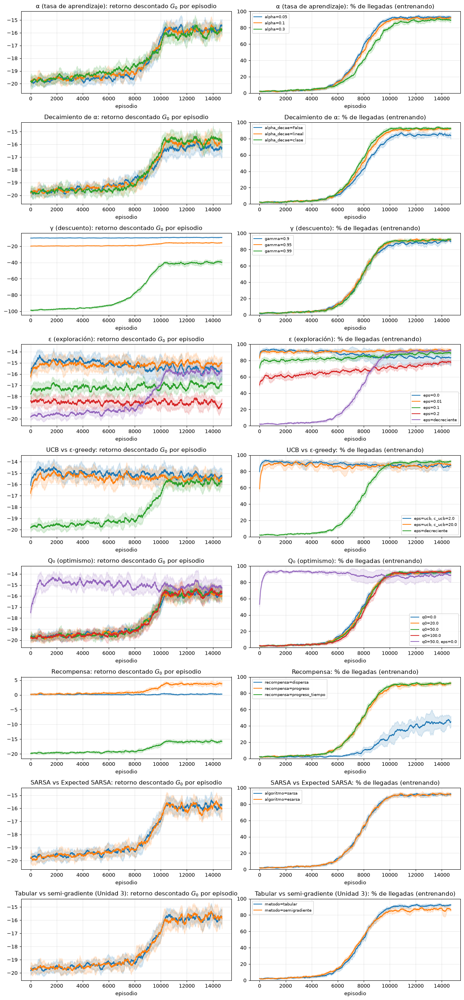

In [9]:
def media_movil(x, v=300):
    return np.convolve(np.asarray(x, float), np.ones(v) / v, mode="valid")

fig, axs = plt.subplots(len(grupos), 2, figsize=(13, 3.1 * len(grupos)))
for fila, (g, lista) in zip(axs, grupos.items()):
    for c in lista:
        hs = [h for h, _ in resultados[clave(c)]]  # media ± desviación entre semillas
        for ax, k, esc in ((fila[0], "retorno", 1), (fila[1], "llego", 100)):
            m = esc * np.array([media_movil(h[k]) for h in hs])
            ln, = ax.plot(m.mean(0), label=etiqueta(c))
            ax.fill_between(range(m.shape[1]), m.mean(0) - m.std(0), m.mean(0) + m.std(0), color=ln.get_color(), alpha=.15)
    fila[0].set(title=f"{g}: retorno descontado $G_0$ por episodio", xlabel="episodio")
    fila[1].set(title=f"{g}: % de llegadas (entrenando)", xlabel="episodio", ylim=(0, 100))
    fila[1].legend(fontsize=8)
plt.tight_layout(); plt.show()

**Cómo leer los resultados**
- `llega_%`: lanzamientos que terminan a < 2 m según el GPS. `llega_en_4min_%`: además lo logra en ≤ 240 s.
- `dist_real_final_m`: cuán cerca quedó **de verdad** (el GPS se equivoca ~2–4 m; esto es lo "aproximado" que se aceptó).
- `tiempo_vs_ideal_%`: 100 % sería ir en línea recta sin girar; lo que sobra es girar, buscar el rumbo y esquivar.
- Diferencias menores que el `±` no son significativas: son ruido del GPS y del azar.
- Diferencias menores que el `IC95` tampoco son significativas.

### Conclusiones de los experimentos (media de 10 semillas)

| Factor | Resultado | Por qué |
|---|---|---|
| **α** | 0.05 → 94.1 % (± 1.4) y 0.1 → 92.8 % parecidos; **0.3 → 86.6 % (± 12.6)** | Con recompensas ruidosas (GPS) un paso grande hace que la tabla oscile; algunas semillas fallan. |
| **Decaimiento de α** | constante 89.0 % (± 7.2); lineal 92.8 %; **fórmula de la Tarea 9: 92.9 % (± 1.8)** | Bajar α al final promedia el ruido. La fórmula de clase fue la más estable. |
| **γ** | **0.9 → 88.4 % (± 10.4)**; 0.95 → 92.8 %; 0.99 → 93.9 % (± 1.0) | Con γ = 0.9 el agente es miope: desde > 40 m el +100 de llegar vale casi 0 ($0.9^{100} \approx 0$). Un γ alto es previsor. |
| **ε** | **0 (greedy) → 81.4 %**; 0.01 → 94.3 % pero solo 48 % en 4 min; **0.1 → 93.2 % y el más rápido (53.4 % en 4 min)**; 0.2 → 83.5 % | Igual que el *10-armed testbed*: sin explorar se estanca en un óptimo local; con demasiada exploración SARSA (on-policy) aprende el valor de una política que se equivoca mucho. Lo mejor es un ε intermedio. |
| **UCB** | c = 2 → 81.4 %; c = 20 → 91.6 %, pero lento (41.5 % en 4 min) | Con c = 2 el bono es diminuto frente a Q de decenas: casi greedy. UCB cuenta visitas por estado y, como dice la tabla de clase, escala mal a muchos estados con ruido. Aquí **no superó** a ε-greedy. |
| **Q₀ (optimismo)** | 0, 20 y 100 parecidos (92–93 %); 50 inestable (± 16.6). **Optimista sin ε: 88.0 % frente a 81.4 % de greedy puro** | El optimismo **sí** genera exploración (mejora 7 puntos al greedy puro), pero no reemplaza a ε: la recompensa por progreso corrige rápido los valores optimistas. |
| **Recompensa** | **dispersa → 51.6 % (± 15.9)**; progreso → 94.2 %; progreso + tiempo → 92.8 % | En una cancha de 105 m la señal de llegar es demasiado escasa. Premiar que **la distancia disminuya** (la idea del equipo) es lo que hace funcionar el aprendizaje. |
| **Expected SARSA** | 87.9 % (± 12.3) frente a SARSA 92.8 % (± 4.3) | En teoría tiene menos varianza, pero aquí la varianza viene del GPS y de los obstáculos, no del sorteo de $A'$; no mejoró y fue menos estable entre semillas. |
| **Semi-gradiente** | 82.0 % (± 19.8), pero el más rápido cuando llega (54.3 % en 4 min) | Generaliza entre estados (menos parámetros), a cambio de no poder representar cada caso por separado: muy inestable entre semillas. |

## 5. Modelo final
Se elige la configuración de **SARSA tabular** con mayor `llega_en_4min_%` medio, que es el objetivo real (llegar **y** en menos de 4 min); en `llega_%` las mejores están dentro de su IC95, así que ese criterio no las distingue. Expected SARSA y semi-gradiente quedan como comparación. Luego se entrena más tiempo (30 000 episodios). Cada 1 000 episodios se **valida** la política greedy en 200 lanzamientos (distintos a los de la prueba final) y se guarda la mejor tabla: con recompensas ruidosas la tabla oscila y la última no siempre es la mejor.

In [10]:
ok = tabla[~tabla.index.get_level_values("variante").str.contains("semigradiente|esarsa")]
grupo_mejor, var_mejor = ok["llega_en_4min_%"].idxmax()
mejor = next(c for g, l in grupos.items() for c in l if g == grupo_mejor and etiqueta(c) == var_mejor)
CFG_FINAL = {**sarsa.BASE, **mejor, "episodios": 30000, "validar_cada": 1000}
print("Configuración final:", CFG_FINAL)
t0 = time.time()
agente, hist = sarsa.entrenar(CFG_FINAL)
print(f"Entrenado en {time.time() - t0:.0f} s")
ev = sarsa.evaluar(agente, n=1000)
pd.DataFrame({k: v for k, v in ev.items() if k != "filas"}).T.round(1)

Configuración final: {'metodo': 'tabular', 'algoritmo': 'sarsa', 'alpha': 0.1, 'alpha_decae': 'lineal', 'gamma': 0.95, 'eps': 0.1, 'c_ucb': 2.0, 'q0': 0.0, 'recompensa': 'progreso_tiempo', 'episodios': 30000, 'semilla': 0, 'validar_cada': 1000, 'n_validacion': 200}


Entrenado en 67 s


,llega_%,llega_en_4min_%,se_sale_%,tiempo_medio_s,dist_real_final_m,tiempo_vs_ideal_%
todos,92.9,55.0,5.6,229.3,3.9,181.8
derecho,91.8,52.6,5.4,242.7,3.8,192.7
al_reves,93.8,57.1,5.8,218.0,4.1,172.6


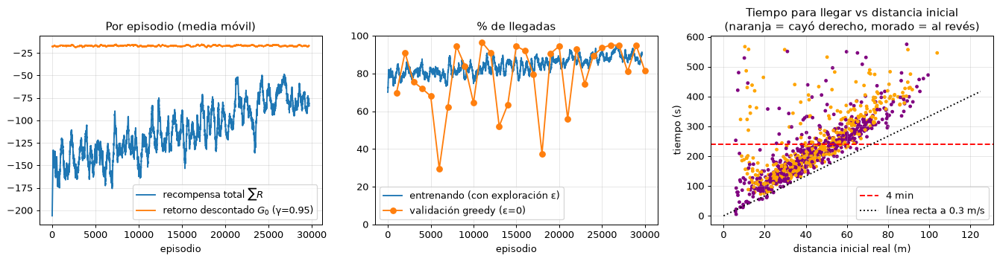

Tiempo ≈ 3.73·d + 66 s  →  a 0.3 m/s llega en 4 min si empieza a ≤ 47 m.
  Para llegar desde  50 m en 4 min haría falta ≈ 0.32 m/s (estimación lineal)
  Para llegar desde  80 m en 4 min haría falta ≈ 0.46 m/s (estimación lineal)
  Para llegar desde 125 m en 4 min haría falta ≈ 0.67 m/s (estimación lineal)
Fallos: 5.4% se salen, 1.7% no llegan en 10 min


In [11]:
f = pd.DataFrame(ev["filas"])
fig, ax = plt.subplots(1, 3, figsize=(15, 4))
ax[0].plot(media_movil(hist["recompensa"]), label="recompensa total $\\sum R$")
ax[0].plot(media_movil(hist["retorno"]), label=f"retorno descontado $G_0$ (γ={CFG_FINAL['gamma']})")
ax[0].set(title="Por episodio (media móvil)", xlabel="episodio"); ax[0].legend()
ax[1].plot(100 * media_movil(hist["llego"]), label="entrenando (con exploración ε)")
ax[1].plot(*zip(*hist["validacion"]), "o-", label="validación greedy (ε=0)")
ax[1].set(title="% de llegadas", xlabel="episodio", ylim=(0, 100)); ax[1].legend()
ll = f[f.llego]
ax[2].scatter(ll.d0, ll.t, s=8, c=np.where(ll.volteado, "purple", "orange"))
ax[2].axhline(ce.LIMITE_PRUEBA, color="red", ls="--", label="4 min")
xs = np.linspace(0, 125, 50); ax[2].plot(xs, xs / ce.VEL, "k:", label="línea recta a 0.3 m/s")
ax[2].set(title="Tiempo para llegar vs distancia inicial\n(naranja = cayó derecho, morado = al revés)",
          xlabel="distancia inicial real (m)", ylabel="tiempo (s)"); ax[2].legend()
plt.tight_layout(); plt.show()

r = np.polyfit(ll.d0, ll.t, 1)
print(f"Tiempo ≈ {r[0]:.2f}·d + {r[1]:.0f} s  →  a 0.3 m/s llega en 4 min si empieza a ≤ {(240 - r[1]) / r[0]:.0f} m.")
for d in (50, 80, 125):
    print(f"  Para llegar desde {d:3d} m en 4 min haría falta ≈ {ce.VEL * (r[0] * d + r[1]) / 240:.2f} m/s (estimación lineal)")
print("Fallos:", f"{(~f.llego & f.fuera).mean():.1%} se salen,", f"{(~f.llego & ~f.fuera).mean():.1%} no llegan en 10 min")

## 6. La política aprendida $\pi(s) = \arg\max_a Q(s,a)$
Cada cuadro es una situación; la letra es la acción elegida: **A**vanzar, **R**etroceder, **I**zquierda, **D**erecha. El color es $V(s)=\max_a Q(s,a)$.

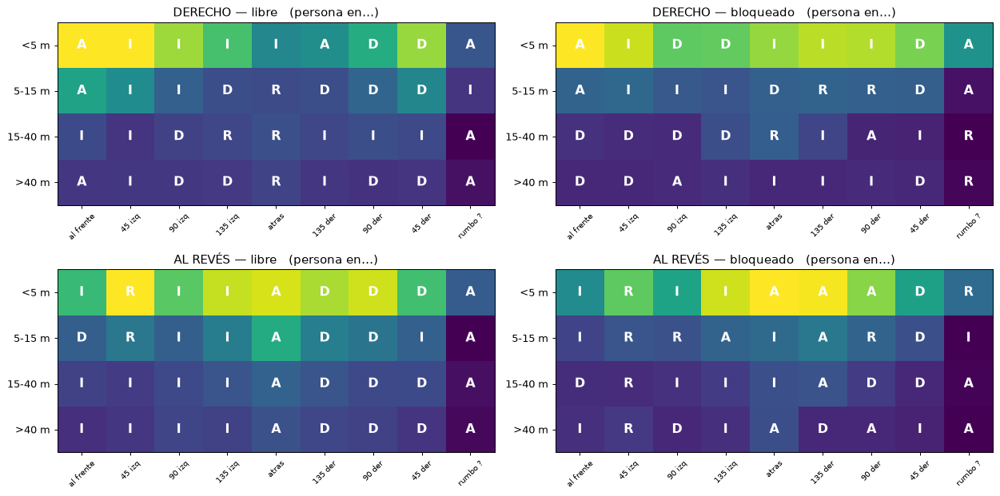

In [12]:
Q = agente.tabla()
fig, axs = plt.subplots(2, 2, figsize=(14, 7))
for F in (0, 1):
    for B in (0, 1):
        ax = axs[F, B]
        V = np.zeros((ce.N_DIST, ce.N_ANG + 1)); L = [[""] * (ce.N_ANG + 1) for _ in range(ce.N_DIST)]
        for d in range(ce.N_DIST):
            for a in range(ce.N_ANG + 1):
                s = ((d * (ce.N_ANG + 1) + a) * 2 + F) * 2 + B
                V[d, a] = Q[s].max(); L[d][a] = "ARID"[int(Q[s].argmax())]
        ax.imshow(V, cmap="viridis", aspect="auto")
        for d in range(ce.N_DIST):
            for a in range(ce.N_ANG + 1):
                ax.text(a, d, L[d][a], ha="center", va="center", color="white", fontsize=13, weight="bold")
        ax.set_xticks(range(ce.N_ANG + 1), ce.NOMBRES_ANG, rotation=45, fontsize=8)
        ax.set_yticks(range(ce.N_DIST), ce.NOMBRES_DIST); ax.grid(False)
        ax.set_title(f"{'AL REVÉS' if F else 'DERECHO'} — {'bloqueado' if B else 'libre'}   (persona en…)")
plt.tight_layout(); plt.show()

### Función de valor de estado $V(s) = \max_a Q(s,a)$
"¿Qué tan bueno es **estar** en este estado?" (retorno esperado siguiendo la política). Debe ser más alto cerca de la persona y con la persona al frente, y más bajo lejos, con rumbo desconocido o bloqueado.

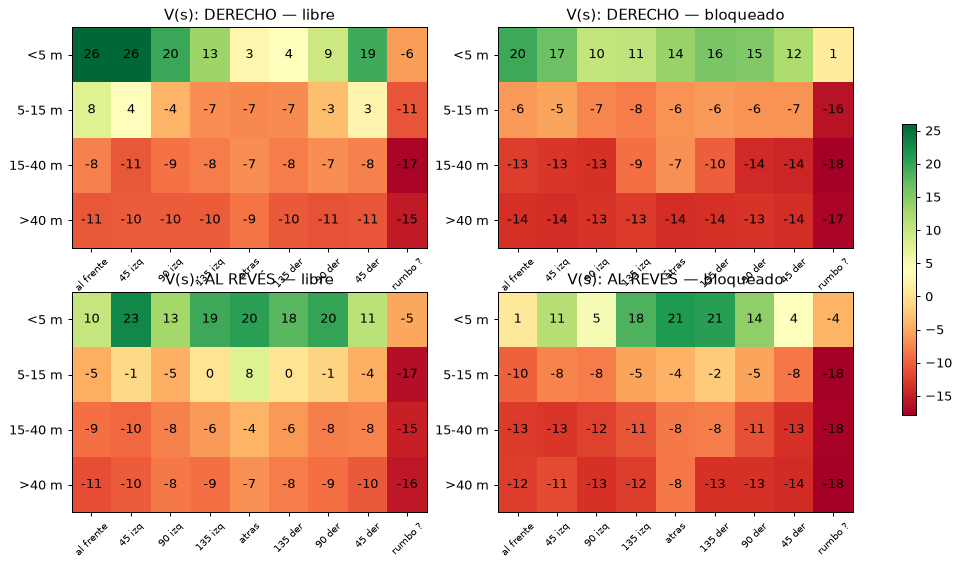

In [13]:
fig, axs = plt.subplots(2, 2, figsize=(14, 7))
for F in (0, 1):
    for B in (0, 1):
        ax = axs[F, B]
        V = np.array([[Q[((d * (ce.N_ANG + 1) + a) * 2 + F) * 2 + B].max() for a in range(ce.N_ANG + 1)] for d in range(ce.N_DIST)])
        im = ax.imshow(V, cmap="RdYlGn", aspect="auto", vmin=Q.max(1).min(), vmax=Q.max(1).max())
        for d in range(ce.N_DIST):
            for a in range(ce.N_ANG + 1):
                ax.text(a, d, f"{V[d, a]:.0f}", ha="center", va="center", fontsize=10)
        ax.set_xticks(range(ce.N_ANG + 1), ce.NOMBRES_ANG, rotation=45, fontsize=8)
        ax.set_yticks(range(ce.N_DIST), ce.NOMBRES_DIST); ax.grid(False)
        ax.set_title(f"V(s): {'AL REVÉS' if F else 'DERECHO'} — {'bloqueado' if B else 'libre'}")
fig.colorbar(im, ax=axs, shrink=.6); plt.show()

**Qué aprendió sobre estar al revés.** Al revés, *Avanzar* mueve el carrito hacia **atrás de la nariz** y los giros quedan invertidos. Nadie se lo programó; compara qué hace en cada caso:

In [14]:
for F in (0, 1):
    print("AL REVÉS" if F else "DERECHO")
    for a in (0, 2, 4, 6, 8):
        acciones = [ce.NOMBRES_ACCION[int(Q[((d * (ce.N_ANG + 1) + a) * 2 + F) * 2].argmax())] for d in range(ce.N_DIST)]
        print(f"   persona {ce.NOMBRES_ANG[a]:12s} ->", " | ".join(f"{ce.NOMBRES_DIST[d]}: {x}" for d, x in enumerate(acciones)))

DERECHO
   persona al frente    -> <5 m: Avanzar | 5-15 m: Avanzar | 15-40 m: Izquierda | >40 m: Avanzar
   persona 90 izq       -> <5 m: Izquierda | 5-15 m: Izquierda | 15-40 m: Derecha | >40 m: Derecha
   persona atras        -> <5 m: Izquierda | 5-15 m: Retroceder | 15-40 m: Retroceder | >40 m: Retroceder
   persona 90 der       -> <5 m: Derecha | 5-15 m: Derecha | 15-40 m: Izquierda | >40 m: Derecha
   persona rumbo ?      -> <5 m: Avanzar | 5-15 m: Izquierda | 15-40 m: Avanzar | >40 m: Avanzar
AL REVÉS
   persona al frente    -> <5 m: Izquierda | 5-15 m: Derecha | 15-40 m: Izquierda | >40 m: Izquierda
   persona 90 izq       -> <5 m: Izquierda | 5-15 m: Izquierda | 15-40 m: Izquierda | >40 m: Izquierda
   persona atras        -> <5 m: Avanzar | 5-15 m: Avanzar | 15-40 m: Avanzar | >40 m: Avanzar
   persona 90 der       -> <5 m: Derecha | 5-15 m: Derecha | 15-40 m: Derecha | >40 m: Derecha
   persona rumbo ?      -> <5 m: Avanzar | 5-15 m: Avanzar | 15-40 m: Avanzar | >40 m: Avanza

Derecho, con la persona **al frente** → *Avanzar*. Al revés, con la persona **atrás de la nariz** → *Avanzar* (que al revés lo lleva justo hacia ella): el agente aprendió a usar la "cola" como frente. Cuando el rumbo aún es desconocido, avanza en recta para que el GPS le dé el rumbo.

## 7. Simulaciones animadas con la política entrenada

### Prueba de fuego: cae **al revés**, **de espaldas** a la persona y con un **obstáculo en medio**

In [15]:
pos, meta = (20.0, 30.0), (60.0, 40.0)
ang_meta = math.atan2(meta[1] - pos[1], meta[0] - pos[0])
opciones = dict(pos=pos, meta=meta, volteado=True, theta=ang_meta + math.pi,
                obstaculos=[(40.0, 35.0, 1.5), (30, 50, 1.0), (75, 20, 1.2), (50, 10, 0.8)])
info, env_f, fotos, acc = sarsa.correr(agente, seed=7, options=opciones, guardar=True)
print("Resultado:", "LLEGÓ" if info["llego"] else "no llegó", f"en {info['t']:.0f} s | distancia real final {info['dist_real']:.1f} m")
animar(fotos, acc, env_f, "Prueba de fuego: al revés, de espaldas y con obstáculo", archivo="prueba_de_fuego.gif")

Resultado: LLEGÓ en 188 s | distancia real final 2.6 m


### Un lanzamiento aleatorio cualquiera

In [16]:
info, env_r, fotos, acc = sarsa.correr(agente, seed=2024, guardar=True)
print("Resultado:", "LLEGÓ" if info["llego"] else "no llegó", f"en {info['t']:.0f} s | {'al revés' if info['volteado'] else 'derecho'} | distancia real final {info['dist_real']:.1f} m")
animar(fotos, acc, env_r, "Lanzamiento aleatorio", archivo="lanzamiento_aleatorio.gif")

Resultado: LLEGÓ en 257 s | al revés | distancia real final 3.4 m


### 12 lanzamientos aleatorios (recorridos completos)

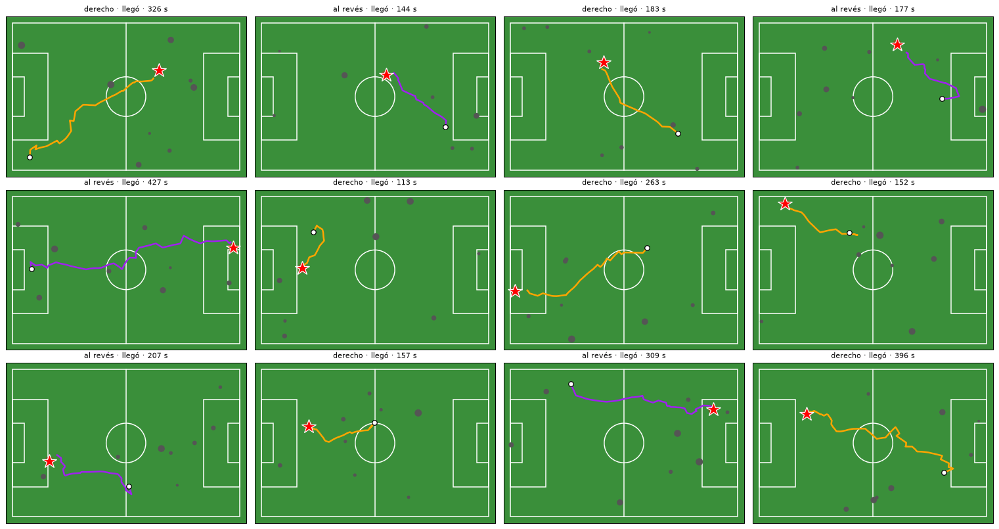

In [17]:
fig, axs = plt.subplots(3, 4, figsize=(17, 9))
for k, ax in enumerate(axs.flat):
    info, e, fotos, _ = sarsa.correr(agente, seed=500 + k, guardar=True)
    dibujar_mundo(ax, e)
    xy = np.array([f["pos"] for f in fotos])
    ax.plot(xy[:, 0], xy[:, 1], color="#a020f0" if e.volteado else "orange", lw=2)
    ax.plot(*xy[0], "wo", mec="k")
    ax.set_title(f"{'al revés' if e.volteado else 'derecho'} · {'llegó' if info['llego'] else ('SALIÓ' if info['fuera'] else 'no llegó')} · {info['t']:.0f} s", fontsize=9)
plt.tight_layout(); plt.show()

## 8. Comparación: SARSA semi-gradiente lineal (Unidad 3)
En vez de una tabla se aprenden **pesos** $\mathbf{w}$: $\hat q(s,a,\mathbf{w}) = \mathbf{w}_a^\top \mathbf{x}(s)$, con características *one-hot* apiladas por acción (sesgo, distancia, ángulo×volteado, bloqueado×volteado → 27 por acción).

$$\mathbf{w} \leftarrow \mathbf{w} + \alpha\big[R + \gamma\,\hat q(S',A',\mathbf{w}) - \hat q(S,A,\mathbf{w})\big]\,\nabla_{\mathbf{w}}\hat q(S,A,\mathbf{w})$$

Usa menos parámetros (108 frente a 576) a cambio de no poder representar cualquier combinación de estado: generaliza entre distancias.

In [18]:
display(tabla.xs("Tabular vs semi-gradiente (Unidad 3)", level=0))
agente_sg, _ = sarsa.entrenar({**CFG_FINAL, "metodo": "semigradiente"})  # también con validación
sarsa.exportar(agente_sg, os.path.join(SALIDA, "semigradiente"))
print("Semi-gradiente (30 000 ep):", {k: round(v, 1) for k, v in sarsa.evaluar(agente_sg, 1000)["todos"].items()})

,llega_%,llega_en_4min_%,se_sale_%,tiempo_medio_s,dist_real_final_m,tiempo_vs_ideal_%,llega_% ±,IC95 llega_%
variante,,,,,,,,
metodo=tabular,92.8,50.5,4.7,238.3,3.8,172.2,4.3,2.6
metodo=semigradiente,82.0,54.3,8.3,207.3,3.7,164.9,19.8,12.3


Semi-gradiente (30 000 ep): {'llega_%': 92.7, 'llega_en_4min_%': 62.1, 'se_sale_%': 6.5, 'tiempo_medio_s': 206.5, 'dist_real_final_m': 3.8, 'tiempo_vs_ideal_%': 147.2}


## 9. Exportar a CSV para la tarjeta

In [19]:
sarsa.exportar(agente, SALIDA)
print(open(os.path.join(SALIDA, "politica.csv")).read()[:600])
print("Archivos:", sorted(os.listdir(SALIDA)))

estado,dist_idx,ang_idx,volteado,bloqueado,accion,accion_nombre,Q_avanzar,Q_retroceder,Q_izquierda,Q_derecha
0,0,0,0,0,0,Avanzar,25.9454,11.5897,12.0707,15.8763
1,0,0,0,1,0,Avanzar,19.5951,6.5598,8.0671,11.3041
2,0,0,1,0,2,Izquierda,-0.0714,0.8595,10.1328,2.2347
3,0,0,1,1,2,Izquierda,-0.5499,0.4477,0.9494,-0.0402
4,0,1,0,0,2,Izquierda,21.2007,12.7219,25.8182,15.0136
5,0,1,0,1,2,Izquierda,7.4578,1.2188,16.5494,9.2280
6,0,1,1,0,1,Retroceder,4.4659,22.9045,11.6784,11.6063
7,0,1,1,1,1,Retroceder,-1.8756,11.4980,-0.6641,-0.5627
8,0,2,0,0,2,Izquierda,13.1686,6.7283,19.6390,7.9088
9,0,2,0,1,3,Derecha
Archivos: ['experimentos.csv', 'lanzamiento_aleatorio.gif', 'politica.csv', 'prueba_de_fuego.gif', 'q_table.csv', 'semigradiente']


### Cómo la usa la tarjeta (sea cual sea): solo **inferencia**, no se entrena allá

```c
// cada 1 s (cuando llega una lectura nueva del GPS):
// 1) GPS -> metros locales (x = Este, y = Norte), igual que en la simulación
dx = (lon_persona - lon_carro) * cos(lat_carro) * 111320.0;
dy = (lat_persona - lat_carro) * 110540.0;
dist = sqrt(dx*dx + dy*dy);
if (dist < 2.0) { parar(); return; }                  // llegó
// 2) F = acelerómetro Z < 0 ;  giroscopio: integrar giro (positivo = antihorario = izquierda),
//    multiplicando por -1 si F = 1
// 3) rumbo: tras 4 m en recta, rumbo = atan2(dy_recta, dx_recta) (+180° si se movía hacia atrás de la nariz)
// 4) ang = atan2(dy, dx) - rumbo  ->  sector a = round(ang / 45°) mod 8   (a = 8 si aún no hay rumbo)
// 5) B = 1 si golpe en acelerómetro o el GPS no avanzó 0.84 m en 8 s empujando; vuelve a 0 tras 6 s en recta sin golpes
// 6) d = 0 si dist<=5, 1 si <=15, 2 si <=40, si no 3
estado = ((d*9 + a)*2 + F)*2 + B;
accion = POLITICA[estado];        // columna "accion" de politica.csv (o argmax de q_table.csv)
mover(accion, 1000 /*ms*/);       // 0 Avanzar, 1 Retroceder, 2 Izquierda, 3 Derecha
```

| Archivo | Contenido |
|---|---|
| `resultados/q_table.csv` | 144 filas (estado) × 4 columnas (acciones): valores Q |
| `resultados/politica.csv` | por estado: sus componentes, la mejor acción y sus Q (legible) |
| `resultados/semigradiente/pesos_semigradiente.csv` | 27 × 4 pesos de la versión Unidad 3 |
| `resultados/experimentos.csv` | tabla de todos los experimentos |
| `resultados/*.gif` | animaciones para la presentación |

**Al construir el carrito hay que medir y actualizar en `cancha_env.py`:** velocidad real (`VEL`), cuánto gira en 1 s (`GIRO`), y la deriva real del giroscopio. Luego se vuelve a correr este notebook y se exporta una tabla nueva.